# iFood Campaign Response Prediction

**Goal:** Predict which customers will accept a marketing campaign — minimizing the cost of contacting non-responders while maintaining meaningful coverage of potential leads.

**Dataset:** 2,240 iFood customers × 29 features | Target: `Response` (14.9% positive rate)

**Best result:** Random Forest + Grid Search → **Precision 0.809 · Recall 0.458 · AUC-ROC 0.895**

---

## Notebook structure

| Part | Topic | Key output |
|------|-------|------------|
| 1 | Statistical hypothesis testing (Z-test) | 22/27 features significantly different between groups |
| 2 | ML modeling — baselines → boosting → hyperparameter tuning | Best model: Random Forest (Grid Search) |
| 3 | Convergence analysis: Z-test vs. feature importance | Full convergence across top 5 ML features |

## Business framing

Each outreach to a customer who will reject the offer has a direct monetary cost (`Z_CostContact`). Therefore:

- **Primary metric: Precision** — minimize false positives (wasted outreach)
- **Constraint: Recall ≥ 0.40** — maintain enough coverage to generate revenue
- **Secondary metric: AUC-ROC** — evaluate overall discriminative power


## Setup

In [ ]:
# Install required packages (skip if already in requirements.txt environment)
!pip install statsmodels lightgbm xgboost catboost scikit-optimize imbalanced-learn -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 6.8 MB/s eta 0:00:00


## Imports & Configuration

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from datetime import datetime

# Estatística
from statsmodels.stats.weightstats import ztest

# Pré-processamento
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from scipy.stats import randint, uniform

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
from skopt import BayesSearchCV
from skopt.space import Integer, Real

# Métricas
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score,
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay
)

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 50)
SEED = 42
print("Imports OK")

Imports OK


---
## 0. Data Loading & Cleaning

The dataset contains **2,240 customers** who were part of a marketing pilot. The column `Response` is the binary target (1 = accepted offer, 0 = rejected) with a **14.9% positive rate** — a class imbalance that will be addressed during modeling.

**Cleaning steps:**
1. Drop non-predictive columns (`ID`, `Z_CostContact`, `Z_Revenue`)
2. Drop 24 rows (~1%) with missing `Income` — too few to impute without bias risk
3. Remove 7 rows with nonsensical `Marital_Status` values (`'YOLO'`, `'Absurd'`, `'Alone'`)
4. Parse dates and engineer new features


In [ ]:
# Load dataset — place data.csv in the data/ folder (see data/README.md)
df = pd.read_csv('../data/data.csv', encoding='utf-8')
print(f'Shape: {df.shape}')
df.head()

Shape original: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


### Remoção de colunas desnecessárias

In [ ]:
# ID: identificador único — não tem valor preditivo
# Z_CostContact e Z_Revenue: valores constantes — não explicam variação entre clientes
df.drop(['ID', 'Z_CostContact', 'Z_Revenue'], axis=1, inplace=True, errors='ignore')
print(f"Shape após drop de colunas: {df.shape}")
df.nunique().sort_values().head(10)

Shape após drop de colunas: (2240, 26)


,0
AcceptedCmp4,2
Response,2
Complain,2
AcceptedCmp2,2
AcceptedCmp1,2
AcceptedCmp5,2
AcceptedCmp3,2
Teenhome,3
Kidhome,3
Education,5


### Análise e tratamento de valores nulos

In [ ]:
print("Valores nulos por coluna:")
print(df.isna().sum()[df.isna().sum() > 0])

# Apenas Income possui nulos (24 linhas = ~1% do dataset)
# Verificando a distribuição de Response entre as linhas com Income nulo
print("\nDistribuição de Response entre linhas com Income=NaN:")
print(df[df.Income.isna()].Response.value_counts())
print(f"\n% de amostras com NaN: {(df.Income.isna().sum()/len(df)*100):.2f}%")
# Como representa apenas 1% e há somente 1 caso positivo entre eles, removemos sem risco de viés
df.dropna(inplace=True)
print(f"Shape após dropna: {df.shape}")

Valores nulos por coluna:
Income    24
dtype: int64

Distribuição de Response entre linhas com Income=NaN:
Response
0    23
1     1
Name: count, dtype: int64

% de amostras com NaN: 1.07%
Shape após dropna: (2216, 26)


### Ajuste de tipos e limpeza de Marital_Status

In [ ]:
# Corrigindo dtypes
df = df.convert_dtypes()
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'])

# Valores incoerentes em Marital_Status
print("Valores únicos em Marital_Status:")
print(df.Marital_Status.value_counts())

# YOLO, Absurd, Alone: valores sem sentido para estado civil real
df = df.loc[~df.Marital_Status.isin(['YOLO', 'Absurd', 'absurd', 'Alone', 'alone'])]
print(f"\nShape após limpeza Marital_Status: {df.shape}")

Valores únicos em Marital_Status:
Marital_Status
Married     857
Together    573
Single      471
Divorced    232
Widow        76
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: Int64

Shape após limpeza Marital_Status: (2209, 26)


---
## 0.2 Feature Engineering

New features derived from the raw data to improve interpretability and model performance:

| Feature | Derivation | Rationale |
|---|---|---|
| `Age` | 2025 − `Year_Birth` | More interpretable than raw birth year |
| `Days_Customer` | days since `Dt_Customer` | Captures relationship tenure |
| `TotalMnt` | sum of all `Mnt*` columns | Overall spending power |
| `TotalPurchases` | sum of all `Num*Purchases` | Total channel activity |
| `TotalAccepted` | sum of `AcceptedCmp1–5` | Historical campaign engagement |
| `TotalDependents` | `Kidhome` + `Teenhome` | Household size signal |


In [ ]:
# Age: mais interpretável que Year_Birth
df['Age'] = 2025 - df['Year_Birth']
df.drop('Year_Birth', axis=1, inplace=True, errors='ignore')

# Days_Customer: há quantos dias o cliente está na base (tempo de relacionamento)
ref_date = df['Dt_Customer'].max()
df['Days_Customer'] = (ref_date - df['Dt_Customer']).dt.days
df.drop('Dt_Customer', axis=1, inplace=True, errors='ignore')

# Total gasto em produtos (soma de todas as categorias)
df['TotalMnt'] = (df['MntWines'] + df['MntFruits'] + df['MntMeatProducts'] +
                  df['MntFishProducts'] + df['MntSweetProducts'] + df['MntGoldProds'])

# Total de compras (todos os canais)
df['TotalPurchases'] = (df['NumWebPurchases'] + df['NumCatalogPurchases'] +
                        df['NumStorePurchases'] + df['NumDealsPurchases'])

# Total de campanhas aceitas anteriormente
df['TotalAccepted'] = (df['AcceptedCmp1'] + df['AcceptedCmp2'] + df['AcceptedCmp3'] +
                       df['AcceptedCmp4'] + df['AcceptedCmp5'])

# Total de dependentes em casa
df['TotalDependents'] = df['Kidhome'] + df['Teenhome']

print("Novas features criadas:")
print([c for c in ['Age','Days_Customer','TotalMnt','TotalPurchases','TotalAccepted','TotalDependents']])
print(f"\nShape final: {df.shape}")
df.head()

Novas features criadas:
['Age', 'Days_Customer', 'TotalMnt', 'TotalPurchases', 'TotalAccepted', 'TotalDependents']

Shape final: (2209, 30)


,Education,Marital_Status,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Age,Days_Customer,TotalMnt,TotalPurchases,TotalAccepted,TotalDependents
0,Graduation,Single,58138,0,0,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,1,68,663,1617,25,0,0
1,Graduation,Single,46344,1,1,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,0,71,113,27,6,0,2
2,Graduation,Together,71613,0,0,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,0,60,312,776,21,0,0
3,Graduation,Together,26646,1,0,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,0,41,139,53,8,0,1
4,PhD,Married,58293,1,0,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,0,44,161,422,19,0,1


### 0.3 Exploratory Analysis

In [ ]:
# Distribuição da variável target
print("Distribuição de Response:")
print(df.Response.value_counts())
print()
print(df.Response.value_counts(normalize=True).map(lambda x: f'{x:.1%}'))

# Há desbalanceamento significativo: ~85% não aceitou, ~15% aceitou
# Isso será tratado nos modelos de ML

Distribuição de Response:
Response
0    1879
1     330
Name: count, dtype: Int64

Response
0    85.1%
1    14.9%
Name: proportion, dtype: object


In [ ]:
# Estatística descritiva das variáveis numéricas
num_cols_all = df.select_dtypes(include='number').columns.tolist()
num_cols_all = [c for c in num_cols_all if c != 'Response']
df[num_cols_all].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Income,2209.0,52243.977818,25198.475858,1730.0,35246.0,51390.0,68627.0,666666.0
Kidhome,2209.0,0.441829,0.537024,0.0,0.0,0.0,1.0,2.0
Teenhome,2209.0,0.505206,0.544318,0.0,0.0,0.0,1.0,2.0
Recency,2209.0,49.076053,28.948177,0.0,24.0,49.0,74.0,99.0
MntWines,2209.0,305.194206,337.688597,0.0,24.0,174.0,505.0,1493.0
MntFruits,2209.0,26.354912,39.800145,0.0,2.0,8.0,33.0,199.0
MntMeatProducts,2209.0,167.161159,224.43659,0.0,16.0,68.0,233.0,1725.0
MntFishProducts,2209.0,37.556813,54.583789,0.0,3.0,12.0,50.0,259.0
MntSweetProducts,2209.0,27.074694,41.113282,0.0,1.0,8.0,33.0,262.0
MntGoldProds,2209.0,43.845179,51.653515,0.0,9.0,24.0,56.0,321.0


---
# Part 1 — Statistical Hypothesis Testing

**Method:** Two-sample Z-test comparing group means between `Response=0` (non-responders, n=1,879) and `Response=1` (responders, n=330).

**Null hypothesis:** The population means are equal (μ₀ = μ₁)

**Decision rule:** Reject H₀ when p-value < α = 0.05 (two-tailed)

**Why Z-test?** Large, approximately normal group sizes (Central Limit Theorem applies).


In [ ]:
# Separando os dois grupos
df0 = df[df.Response == 0]  # Não aceitou
df1 = df[df.Response == 1]  # Aceitou

print(f"Grupo Response=0: {len(df0)} clientes")
print(f"Grupo Response=1: {len(df1)} clientes")

Grupo Response=0: 1879 clientes
Grupo Response=1: 330 clientes


In [ ]:
# Aplicando o Teste Z para todas as variáveis numéricas
# A função ztest() da statsmodels realiza o teste bicaudal (two-sided) por padrão

resultados_z = []

for col in num_cols_all:
    g0 = df0[col].dropna().values
    g1 = df1[col].dropna().values

    z_stat, p_valor = ztest(g0, g1, value=0)  # H0: diferença de médias = 0

    resultados_z.append({
        'Feature': col,
        'Média Response=0': round(g0.mean(), 3),
        'Média Response=1': round(g1.mean(), 3),
        'Diferença (1-0)': round(g1.mean() - g0.mean(), 3),
        'Z-statístico': round(z_stat, 4),
        'p-valor': round(p_valor, 6),
        'Significativa (α=0.05)': 'Sim ✓' if p_valor < 0.05 else 'Não'
    })

df_ztest = pd.DataFrame(resultados_z).sort_values('p-valor')
df_ztest

,Feature,Média Response=0,Média Response=1,Diferença (1-0),Z-statístico,p-valor,Significativa (α=0.05)
0,Income,50835.903,60261.473,9425.570,-6.3220,0.000000,Sim ✓
2,Teenhome,0.541,0.303,-0.238,7.4045,0.000000,Sim ✓
3,Recency,51.498,35.288,-16.210,9.5722,0.000000,Sim ✓
4,MntWines,270.150,504.736,234.587,-12.0105,0.000000,Sim ✓
6,MntMeatProducts,144.555,295.882,151.327,-11.6352,0.000000,Sim ✓
5,MntFruits,24.316,37.967,13.651,-5.7887,0.000000,Sim ✓
7,MntFishProducts,35.105,51.518,16.413,-5.0660,0.000000,Sim ✓
8,MntSweetProducts,25.064,38.521,13.457,-5.5203,0.000000,Sim ✓
15,AcceptedCmp3,0.046,0.230,0.185,-12.2509,0.000000,Sim ✓
9,MntGoldProds,40.854,60.879,20.025,-6.5568,0.000000,Sim ✓


In [ ]:
# Resumo: features com diferença estatisticamente significativa
features_sig = df_ztest[df_ztest['p-valor'] < 0.05]['Feature'].tolist()
features_nao_sig = df_ztest[df_ztest['p-valor'] >= 0.05]['Feature'].tolist()

print(f"Features SIGNIFICATIVAS ({len(features_sig)}):")
for f in features_sig:
    row = df_ztest[df_ztest.Feature == f].iloc[0]
    print(f"  {f:30s}  p={row['p-valor']:.6f}  |  μ₀={row['Média Response=0']:.2f}  μ₁={row['Média Response=1']:.2f}")

print(f"\nFeatures NÃO significativas ({len(features_nao_sig)}):")
for f in features_nao_sig:
    row = df_ztest[df_ztest.Feature == f].iloc[0]
    print(f"  {f:30s}  p={row['p-valor']:.4f}")

Features SIGNIFICATIVAS (22):
  Income                          p=0.000000  |  μ₀=50835.90  μ₁=60261.47
  Teenhome                        p=0.000000  |  μ₀=0.54  μ₁=0.30
  Recency                         p=0.000000  |  μ₀=51.50  μ₁=35.29
  MntWines                        p=0.000000  |  μ₀=270.15  μ₁=504.74
  MntMeatProducts                 p=0.000000  |  μ₀=144.56  μ₁=295.88
  MntFruits                       p=0.000000  |  μ₀=24.32  μ₁=37.97
  MntFishProducts                 p=0.000000  |  μ₀=35.10  μ₁=51.52
  MntSweetProducts                p=0.000000  |  μ₀=25.06  μ₁=38.52
  AcceptedCmp3                    p=0.000000  |  μ₀=0.05  μ₁=0.23
  MntGoldProds                    p=0.000000  |  μ₀=40.85  μ₁=60.88
  NumWebPurchases                 p=0.000000  |  μ₀=3.91  μ₁=5.08
  NumCatalogPurchases             p=0.000000  |  μ₀=2.40  μ₁=4.20
  AcceptedCmp2                    p=0.000000  |  μ₀=0.01  μ₁=0.06
  AcceptedCmp1                    p=0.000000  |  μ₀=0.03  μ₁=0.24
  AcceptedCmp5      

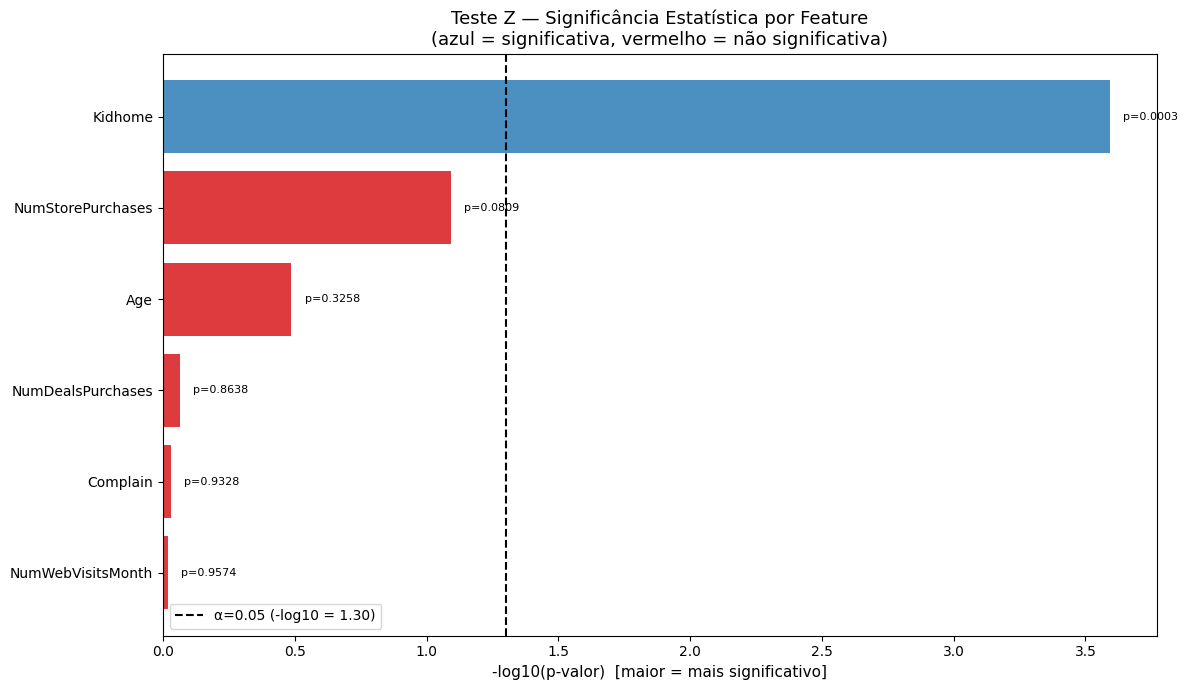

Azul: 22 features significativas | Vermelho: 5 não significativas


In [ ]:
# Visualização 1: p-valores de todas as features com linha de corte em α=0.05
fig, ax = plt.subplots(figsize=(12, 7))

colors = ['#2c7bb6' if p < 0.05 else '#d7191c' for p in df_ztest['p-valor']]
bars = ax.barh(df_ztest['Feature'], -np.log10(df_ztest['p-valor']), color=colors, alpha=0.85)

# Linha de corte (α=0.05 → -log10(0.05) ≈ 1.30)
ax.axvline(x=-np.log10(0.05), color='black', linestyle='--', linewidth=1.5,
           label=f'α=0.05 (-log10 = {-np.log10(0.05):.2f})')

ax.set_xlabel('-log10(p-valor)  [maior = mais significativo]', fontsize=11)
ax.set_title('Teste Z — Significância Estatística por Feature\n(azul = significativa, vermelho = não significativa)', fontsize=13)
ax.legend()
ax.invert_yaxis()

# Anotação dos p-valores
for bar, p in zip(bars, df_ztest['p-valor']):
    ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
            f'p={p:.4f}', va='center', fontsize=8)

plt.tight_layout()
plt.show()
print(f"Azul: {len(features_sig)} features significativas | Vermelho: {len(features_nao_sig)} não significativas")

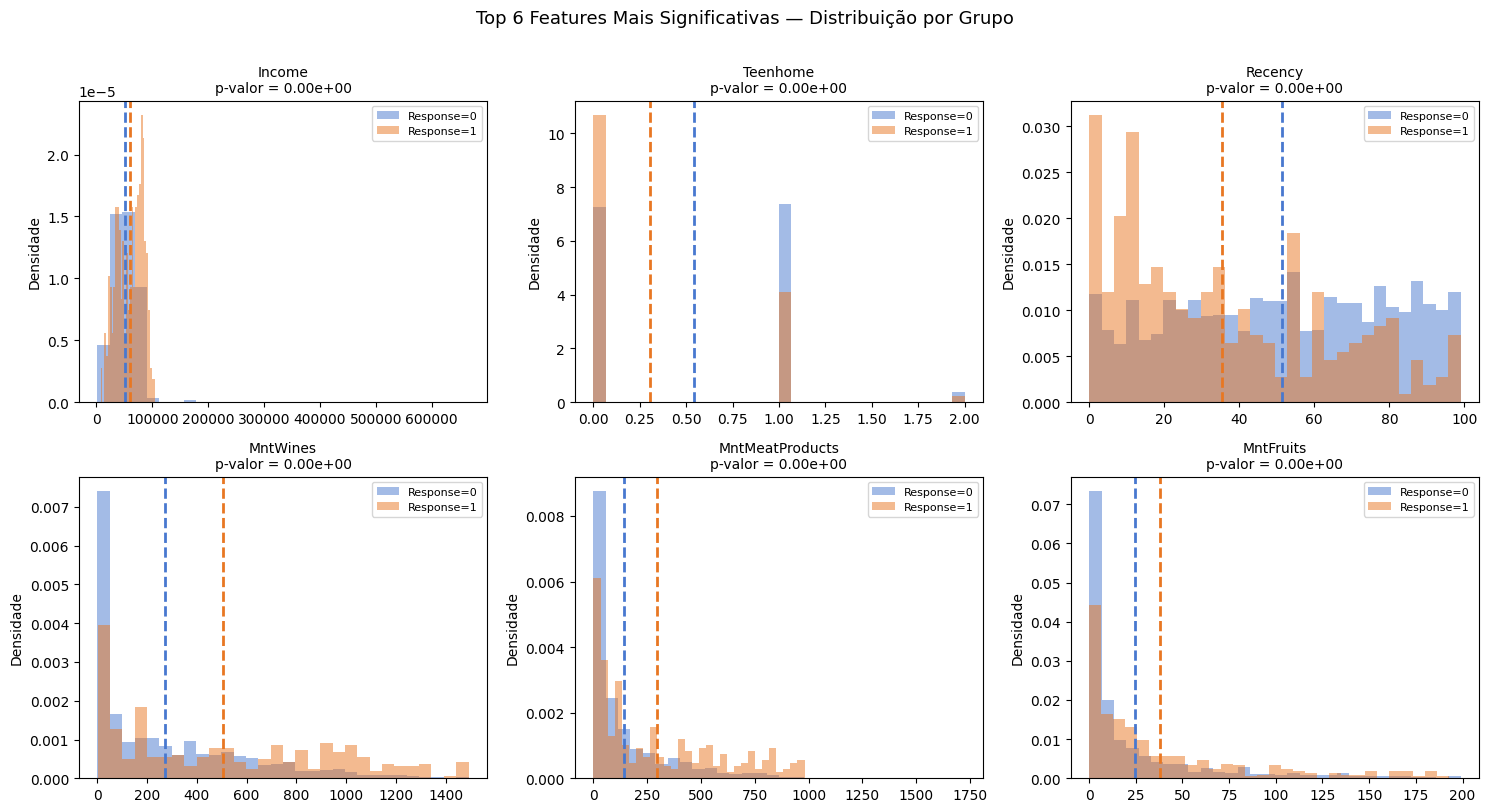

In [ ]:
# Visualização 2: KDE das 6 features mais significativas — comparação entre grupos
top6 = df_ztest.head(6)['Feature'].tolist()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(top6):
    ax = axes[i]
    p_val = df_ztest[df_ztest.Feature == col]['p-valor'].values[0]

    ax.hist(df0[col], bins=30, alpha=0.5, label='Response=0', color='#4878cf', density=True)
    ax.hist(df1[col], bins=30, alpha=0.5, label='Response=1', color='#e87722', density=True)

    ax.axvline(df0[col].mean(), color='#4878cf', linestyle='--', linewidth=2)
    ax.axvline(df1[col].mean(), color='#e87722', linestyle='--', linewidth=2)

    ax.set_title(f'{col}\np-valor = {p_val:.2e}', fontsize=10)
    ax.legend(fontsize=8)
    ax.set_ylabel('Densidade')

plt.suptitle('Top 6 Features Mais Significativas — Distribuição por Grupo', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### Part 1 Conclusions

**22 out of 27 numeric features** showed statistically significant differences between the two groups (p < 0.05). Key patterns:

- **Spending** (`MntWines`, `MntMeatProducts`, `TotalMnt`): responders spend significantly more across all categories
- **Purchase channels** (`NumCatalogPurchases`, `NumStorePurchases`): responders are more active buyers
- **Income**: responders have higher household income
- **Campaign history** (`TotalAccepted`): prior acceptance is the strongest behavioral predictor
- **Recency**: responders engaged more recently (lower days since last purchase)
- **Teenhome**: fewer teenagers at home is associated with acceptance — likely a disposable income proxy

Features **not significant**: `NumDealsPurchases`, `NumWebVisitsMonth`, `Complain`, `Age`, `Kidhome` — these will be deprioritized but kept for ML to decide.


---
---
# PARTE 2 — Machine Learning & Modelling

## Justificativa da Métrica

O problema de negócio é **campanha de marketing por telefone**. O custo principal é contactar clientes que vão recusar (falso positivo = gasto desnecessário). Por isso:

- **Métrica principal: Precision** — dos clientes que o modelo diz que vão aceitar, quantos realmente aceitam?
- **Métrica secundária: Recall ≥ 0.40** — não queremos perder todos os potenciais clientes
- Acompanhamos também **F1-Score** e **AUC-ROC** para visão geral

> **Não usamos Accuracy** pois com 85% de Response=0, um modelo que sempre prevê "não aceita" acertaria 85% e seria inútil.


---
## Part 2 — Machine Learning

**Pipeline architecture:** `ColumnTransformer` for separate numeric/categorical preprocessing + `Pipeline` for clean train/test isolation. All transformers are fit only on training data to prevent leakage.

**Evaluation protocol:** Stratified 75/25 train-test split + 5-fold `StratifiedKFold` cross-validation (preserves class ratio across folds).

**Class imbalance strategy:** `class_weight='balanced'` (most models), SMOTE for tree baseline, `scale_pos_weight` for XGBoost.


In [ ]:
# Definindo X e y
X = df.drop('Response', axis=1)
y = df['Response'].astype(int)

# Identificando colunas categóricas e numéricas
cat_cols = X.select_dtypes(include=['string', 'object', 'category']).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

print(f"Features numéricas ({len(num_cols)}): {num_cols}")
print(f"Features categóricas ({len(cat_cols)}): {cat_cols}")
print(f"\nShape X: {X.shape} | Shape y: {y.shape}")

Features numéricas (27): ['Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Age', 'Days_Customer', 'TotalMnt', 'TotalPurchases', 'TotalAccepted', 'TotalDependents']
Features categóricas (2): ['Education', 'Marital_Status']

Shape X: (2209, 29) | Shape y: (2209,)


In [ ]:
# Train-Test Split estratificado (mantém proporção de 85/15 em ambos os conjuntos)
Xtrain, Xtest, ytrain, ytest = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)

print(f"Treino:  {Xtrain.shape[0]} amostras | Response=1: {ytrain.sum()} ({ytrain.mean():.1%})")
print(f"Teste:   {Xtest.shape[0]} amostras  | Response=1: {ytest.sum()} ({ytest.mean():.1%})")

Treino:  1656 amostras | Response=1: 247 (14.9%)
Teste:   553 amostras  | Response=1: 83 (15.0%)


In [ ]:
# ─── Pipelines de pré-processamento ───
# Pipeline para modelos lineares (com normalização)
num_pipe_linear = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline para modelos baseados em árvore (sem normalização)
num_pipe_tree = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor_linear = ColumnTransformer([
    ('num', num_pipe_linear, num_cols),
    ('cat', cat_pipe, cat_cols)
])

preprocessor_tree = ColumnTransformer([
    ('num', num_pipe_tree, num_cols),
    ('cat', cat_pipe, cat_cols)
])

print("Pipelines de pré-processamento configurados.")

Pipelines de pré-processamento configurados.


In [ ]:
# ─── Função auxiliar para calcular e exibir métricas ───
def avaliar_modelo(nome, ytest, ypred, yproba=None):
    """Retorna dicionário com as métricas principais do modelo."""
    metricas = {
        'Modelo': nome,
        'Precision': round(precision_score(ytest, ypred, zero_division=0), 4),
        'Recall':    round(recall_score(ytest, ypred, zero_division=0), 4),
        'F1-Score':  round(f1_score(ytest, ypred, zero_division=0), 4),
        'AUC-ROC':   round(roc_auc_score(ytest, yproba if yproba is not None else ypred), 4),
        'Accuracy':  round(accuracy_score(ytest, ypred), 4),
    }
    return metricas

# Tabela comparativa global
leaderboard = []

---
## 2.1 Modelos Baseline

Estabelecemos três modelos de referência para comparação. O modelo de ML "vencedor" precisa superar estes baselines para justificar sua complexidade.


### Baseline 1 — Regressão Logística

In [ ]:
# Regressão Logística
# class_weight='balanced': penaliza mais erros na classe minoritária (Response=1)
# Normalização é essencial para modelos lineares: evita que variáveis com maior escala dominem

lr_pipe = Pipeline([
    ('preprocessor', preprocessor_linear),
    ('model', LogisticRegression(
        C=1.0,
        class_weight='balanced',
        max_iter=2000,
        random_state=SEED
    ))
])

lr_pipe.fit(Xtrain, ytrain)
ypred_lr = lr_pipe.predict(Xtest)
yproba_lr = lr_pipe.predict_proba(Xtest)[:, 1]

print("REGRESSÃO LOGÍSTICA")
print(classification_report(ytest, ypred_lr, target_names=['Não aceitou', 'Aceitou']))

metricas_lr = avaliar_modelo('Logistic Regression (baseline)', ytest, ypred_lr, yproba_lr)
leaderboard.append(metricas_lr)

REGRESSÃO LOGÍSTICA
              precision    recall  f1-score   support

 Não aceitou       0.96      0.81      0.88       470
     Aceitou       0.43      0.83      0.57        83

    accuracy                           0.81       553
   macro avg       0.70      0.82      0.72       553
weighted avg       0.88      0.81      0.83       553



### Baseline 2 — Decision Tree

In [ ]:
# Decision Tree com pruning para evitar overfitting
# Sem max_depth, a árvore cresce até explicar cada amostra individualmente (treino=100%, teste≈50%)
# SMOTE para balancear as classes antes do treino

sm = SMOTE(random_state=SEED)
Xtrain_sm, ytrain_sm = sm.fit_resample(
    preprocessor_tree.fit_transform(Xtrain),
    ytrain
)
Xtest_tr = preprocessor_tree.transform(Xtest)

print(f"Após SMOTE: {pd.Series(ytrain_sm).value_counts().to_dict()}")

dt_model = DecisionTreeClassifier(
    max_depth=6,
    min_samples_leaf=15,
    random_state=SEED
)
dt_model.fit(Xtrain_sm, ytrain_sm)
ypred_dt = dt_model.predict(Xtest_tr)
yproba_dt = dt_model.predict_proba(Xtest_tr)[:, 1]

print("\nDECISION TREE")
print(classification_report(ytest, ypred_dt, target_names=['Não aceitou', 'Aceitou']))

metricas_dt = avaliar_modelo('Decision Tree + SMOTE (baseline)', ytest, ypred_dt, yproba_dt)
leaderboard.append(metricas_dt)

Após SMOTE: {1: 1409, 0: 1409}

DECISION TREE
              precision    recall  f1-score   support

 Não aceitou       0.91      0.86      0.88       470
     Aceitou       0.39      0.52      0.45        83

    accuracy                           0.81       553
   macro avg       0.65      0.69      0.66       553
weighted avg       0.83      0.81      0.82       553



### Baseline 3 — Random Forest

In [ ]:
# Random Forest: ensemble de árvores treinadas em subamostras diferentes
# balanced_subsample: aplica balanceamento em cada bootstrap sample
# n_jobs=-1: usa todos os núcleos disponíveis

rf_base = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('model', RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=4,
        class_weight='balanced_subsample',
        n_jobs=-1,
        random_state=SEED
    ))
])

rf_base.fit(Xtrain, ytrain)
ypred_rf = rf_base.predict(Xtest)
yproba_rf = rf_base.predict_proba(Xtest)[:, 1]

print("RANDOM FOREST")
print(classification_report(ytest, ypred_rf, target_names=['Não aceitou', 'Aceitou']))

metricas_rf = avaliar_modelo('Random Forest (baseline)', ytest, ypred_rf, yproba_rf)
leaderboard.append(metricas_rf)

RANDOM FOREST
              precision    recall  f1-score   support

 Não aceitou       0.93      0.96      0.94       470
     Aceitou       0.70      0.59      0.64        83

    accuracy                           0.90       553
   macro avg       0.81      0.77      0.79       553
weighted avg       0.90      0.90      0.90       553



In [ ]:
# Comparação dos baselines
df_baselines = pd.DataFrame(leaderboard)
df_baselines.sort_values('Precision', ascending=False).style.highlight_max(
    subset=['Precision','Recall','F1-Score','AUC-ROC'], color='#d4edda'
).highlight_min(subset=['Precision','Recall','F1-Score','AUC-ROC'], color='#f8d7da')

,Modelo,Precision,Recall,F1-Score,AUC-ROC,Accuracy
2,Random Forest (baseline),0.700000,0.590400,0.640500,0.891300,0.900500
0,Logistic Regression (baseline),0.434000,0.831300,0.570200,0.913900,0.811900
1,Decision Tree + SMOTE (baseline),0.390900,0.518100,0.445600,0.818500,0.806500


---
## 2.2 Família de Boosting

Modelos de boosting treinam árvores **sequencialmente**, onde cada nova árvore corrige os erros da anterior. Geralmente superam modelos únicos e random forests em dados tabulares.

| Modelo | Diferencial |
|--------|-------------|
| **LightGBM** | Cresce leaf-wise (mais rápido), eficiente em memória |
| **XGBoost** | Regularização L1/L2 nativa, robusto e amplamente testado |
| **CatBoost** | Excelente tratamento nativo de variáveis categóricas |


### Boosting 1 — LightGBM

In [ ]:
lgbm_pipe = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('model', LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,    # passo conservador: aprende devagar, generaliza melhor
        num_leaves=31,         # complexidade das árvores
        max_depth=-1,          # sem limite explícito (controlado por num_leaves)
        class_weight='balanced',
        n_jobs=-1,
        random_state=SEED,
        verbose=-1
    ))
])

lgbm_pipe.fit(Xtrain, ytrain)
ypred_lgbm = lgbm_pipe.predict(Xtest)
yproba_lgbm = lgbm_pipe.predict_proba(Xtest)[:, 1]

print("LIGHTGBM")
print(classification_report(ytest, ypred_lgbm, target_names=['Não aceitou', 'Aceitou']))
leaderboard.append(avaliar_modelo('LightGBM (baseline)', ytest, ypred_lgbm, yproba_lgbm))

LIGHTGBM
              precision    recall  f1-score   support

 Não aceitou       0.92      0.95      0.94       470
     Aceitou       0.66      0.55      0.60        83

    accuracy                           0.89       553
   macro avg       0.79      0.75      0.77       553
weighted avg       0.88      0.89      0.89       553



### Boosting 2 — XGBoost

In [ ]:
# Calculando scale_pos_weight para lidar com o desbalanceamento
scale_pw = (ytrain == 0).sum() / (ytrain == 1).sum()
print(f"scale_pos_weight = {scale_pw:.2f} (penaliza erros na classe positiva)")

xgb_pipe = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('model', XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,          # amostragem de linhas por árvore (evita overfitting)
        colsample_bytree=0.8,   # amostragem de colunas por árvore
        scale_pos_weight=scale_pw,
        eval_metric='logloss',
        n_jobs=-1,
        random_state=SEED
    ))
])

xgb_pipe.fit(Xtrain, ytrain)
ypred_xgb = xgb_pipe.predict(Xtest)
yproba_xgb = xgb_pipe.predict_proba(Xtest)[:, 1]

print("\nXGBOOST")
print(classification_report(ytest, ypred_xgb, target_names=['Não aceitou', 'Aceitou']))
leaderboard.append(avaliar_modelo('XGBoost (baseline)', ytest, ypred_xgb, yproba_xgb))

scale_pos_weight = 5.70 (penaliza erros na classe positiva)

XGBOOST
              precision    recall  f1-score   support

 Não aceitou       0.94      0.93      0.93       470
     Aceitou       0.60      0.64      0.62        83

    accuracy                           0.88       553
   macro avg       0.77      0.78      0.78       553
weighted avg       0.89      0.88      0.88       553



### Boosting 3 — CatBoost

In [ ]:
cat_pipe = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('model', CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        auto_class_weights='Balanced',  # trata desbalanceamento automaticamente
        verbose=0,
        random_seed=SEED
    ))
])

cat_pipe.fit(Xtrain, ytrain)
ypred_cat = cat_pipe.predict(Xtest)
yproba_cat = cat_pipe.predict_proba(Xtest)[:, 1]

print("CATBOOST")
print(classification_report(ytest, ypred_cat, target_names=['Não aceitou', 'Aceitou']))
leaderboard.append(avaliar_modelo('CatBoost (baseline)', ytest, ypred_cat, yproba_cat))

CATBOOST
              precision    recall  f1-score   support

 Não aceitou       0.93      0.94      0.93       470
     Aceitou       0.63      0.61      0.62        83

    accuracy                           0.89       553
   macro avg       0.78      0.78      0.78       553
weighted avg       0.89      0.89      0.89       553



In [ ]:
# Leaderboard após baselines + boosting
df_lb = pd.DataFrame(leaderboard).sort_values('Precision', ascending=False)
df_lb.reset_index(drop=True, inplace=True)
df_lb.style.highlight_max(
    subset=['Precision','Recall','F1-Score','AUC-ROC'], color='#d4edda'
).format({'Precision':'{:.4f}','Recall':'{:.4f}','F1-Score':'{:.4f}','AUC-ROC':'{:.4f}','Accuracy':'{:.4f}'})

,Modelo,Precision,Recall,F1-Score,AUC-ROC,Accuracy
0,Random Forest (baseline),0.7000,0.5904,0.6405,0.8913,0.9005
1,LightGBM (baseline),0.6571,0.5542,0.6013,0.9097,0.8897
2,CatBoost (baseline),0.6296,0.6145,0.6220,0.9130,0.8879
3,XGBoost (baseline),0.6023,0.6386,0.6199,0.9167,0.8825
4,Logistic Regression (baseline),0.4340,0.8313,0.5702,0.9139,0.8119
5,Decision Tree + SMOTE (baseline),0.3909,0.5181,0.4456,0.8185,0.8065


---
## 2.3 Análise de Threshold

O threshold padrão de 0.5 significa: "prevejo Response=1 quando a probabilidade ≥ 50%". Ajustando o threshold conseguimos equilibrar Precision e Recall conforme o objetivo de negócio.


In [ ]:
def analisar_threshold(nome, ytest, yproba, recall_min=0.40):
    """Analisa precision/recall em diferentes thresholds e retorna o melhor para negócio."""
    resultados = []
    for thr in np.arange(0.1, 0.9, 0.05):
        ypred = (yproba >= thr).astype(int)
        p = precision_score(ytest, ypred, zero_division=0)
        r = recall_score(ytest, ypred, zero_division=0)
        f = f1_score(ytest, ypred, zero_division=0)
        resultados.append({'threshold': round(thr, 2), 'precision': p, 'recall': r, 'f1': f})
    df_thr = pd.DataFrame(resultados)

    # Melhor threshold: maximiza precision com recall mínimo
    df_validos = df_thr[df_thr.recall >= recall_min]
    melhor = df_validos.sort_values('precision', ascending=False).iloc[0] if len(df_validos) > 0 else df_thr.iloc[0]

    return df_thr, melhor

# Aplicar no melhor modelo boosting (CatBoost geralmente performa bem)
for nome, yproba in [('LightGBM', yproba_lgbm), ('XGBoost', yproba_xgb), ('CatBoost', yproba_cat)]:
    df_thr, melhor = analisar_threshold(nome, ytest, yproba)
    print(f"{nome} — Melhor threshold (recall≥0.40): {melhor['threshold']:.2f}  |  "
          f"Precision={melhor['precision']:.4f}  Recall={melhor['recall']:.4f}  F1={melhor['f1']:.4f}")

LightGBM — Melhor threshold (recall≥0.40): 0.75  |  Precision=0.7551  Recall=0.4458  F1=0.5606
XGBoost — Melhor threshold (recall≥0.40): 0.85  |  Precision=0.8780  Recall=0.4337  F1=0.5806
CatBoost — Melhor threshold (recall≥0.40): 0.80  |  Precision=0.8000  Recall=0.4337  F1=0.5625


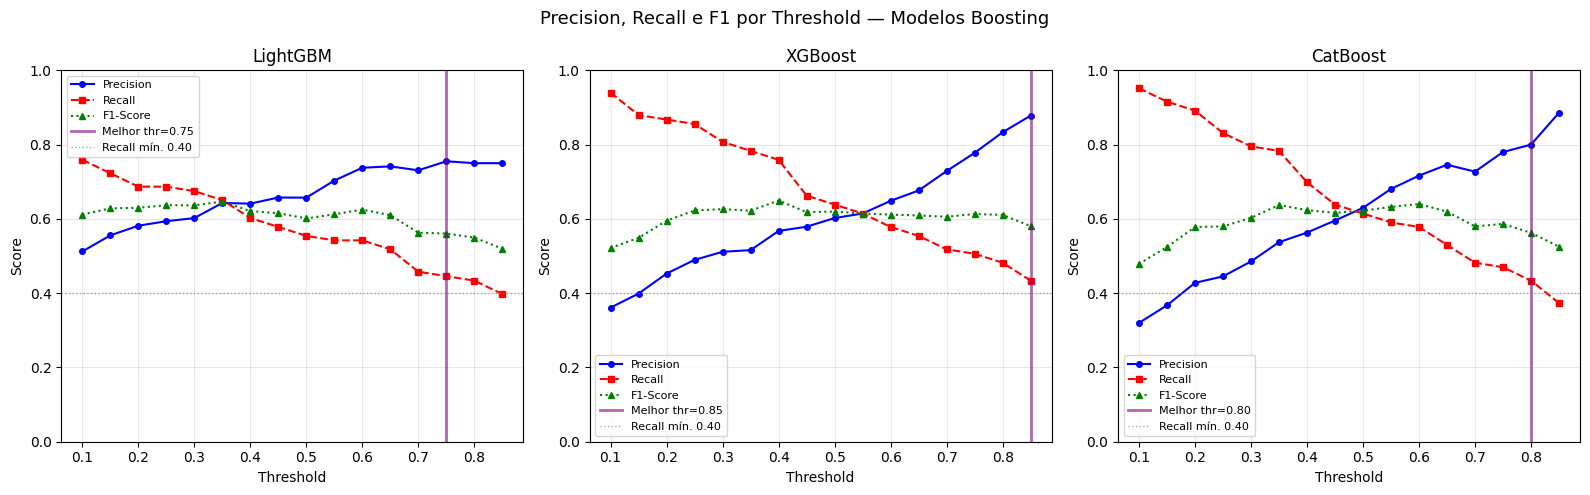

In [ ]:
# Gráfico Precision-Recall por threshold
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (nome, yproba) in zip(axes, [('LightGBM', yproba_lgbm),
                                       ('XGBoost', yproba_xgb),
                                       ('CatBoost', yproba_cat)]):
    df_thr, melhor = analisar_threshold(nome, ytest, yproba)
    ax.plot(df_thr.threshold, df_thr.precision, 'b-o', markersize=4, label='Precision')
    ax.plot(df_thr.threshold, df_thr.recall, 'r--s', markersize=4, label='Recall')
    ax.plot(df_thr.threshold, df_thr.f1, 'g:^', markersize=4, label='F1-Score')
    ax.axvline(melhor['threshold'], color='purple', linewidth=2, alpha=0.6,
               label=f"Melhor thr={melhor['threshold']:.2f}")
    ax.axhline(0.40, color='gray', linewidth=1, linestyle=':', alpha=0.7, label='Recall mín. 0.40')
    ax.set_title(f'{nome}', fontsize=12)
    ax.set_xlabel('Threshold')
    ax.set_ylabel('Score')
    ax.legend(fontsize=8)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)

plt.suptitle('Precision, Recall e F1 por Threshold — Modelos Boosting', fontsize=13)
plt.tight_layout()
plt.show()

---
## 2.4 Tuning de Hiperparâmetros

Aplicamos três estratégias de busca de hiperparâmetros, do mais simples ao mais sofisticado:

| Estratégia | Descrição | Vantagem | Limitação |
|------------|-----------|----------|-----------|
| **Grid Search** | Testa todas as combinações de uma grade | Exaustivo, garante o melhor da grade | Lento para grades grandes |
| **Randomized Search** | Sorteia combinações aleatoriamente | Mais eficiente computacionalmente | Pode perder o ótimo |
| **Bayesian Optimization** | Usa resultados anteriores para guiar a busca | Mais inteligente, converge mais rápido | Mais complexo de configurar |


In [ ]:
# Validação cruzada estratificada para todos os experimentos de tuning
# Estratificada: mantém proporção 85/15 em cada fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("Configuração de cross-validation: StratifiedKFold(n_splits=5)")

Configuração de cross-validation: StratifiedKFold(n_splits=5)


### Tuning 1 — Grid Search no Random Forest

In [ ]:
# Grid Search: testa TODAS as combinações da grade
# 2 × 3 × 2 × 2 × 2 = 48 combinações × 5 folds = 240 treinos
rf_gs_pipe = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('model', RandomForestClassifier(n_jobs=-1, random_state=SEED))
])

rf_param_grid = {
    'model__n_estimators': [200, 300],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [5, 10],
    'model__min_samples_leaf': [2, 4],
    'model__class_weight': ['balanced', 'balanced_subsample']
}

rf_grid_search = GridSearchCV(
    rf_gs_pipe,
    param_grid=rf_param_grid,
    scoring='precision',   # otimiza precision, alinhado ao objetivo de negócio
    cv=cv,
    n_jobs=-1,
    verbose=0
)
rf_grid_search.fit(Xtrain, ytrain)

print(f"Melhores parâmetros (Grid Search RF): {rf_grid_search.best_params_}")
print(f"Melhor precision (CV): {rf_grid_search.best_score_:.4f}")

ypred_rf_gs = rf_grid_search.predict(Xtest)
yproba_rf_gs = rf_grid_search.predict_proba(Xtest)[:, 1]
print(classification_report(ytest, ypred_rf_gs, target_names=['Não aceitou', 'Aceitou']))
leaderboard.append(avaliar_modelo('Random Forest (Grid Search)', ytest, ypred_rf_gs, yproba_rf_gs))

Melhores parâmetros (Grid Search RF): {'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 300}
Melhor precision (CV): 0.6662
              precision    recall  f1-score   support

 Não aceitou       0.91      0.98      0.94       470
     Aceitou       0.81      0.46      0.58        83

    accuracy                           0.90       553
   macro avg       0.86      0.72      0.76       553
weighted avg       0.90      0.90      0.89       553



### Tuning 2 — Randomized Search no LightGBM

In [ ]:
# Randomized Search: sorteia n_iter=20 combinações do espaço de distribuições
# Muito mais eficiente que Grid Search para espaços grandes

lgbm_rs_pipe = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('model', LGBMClassifier(class_weight='balanced', n_jobs=-1,
                              random_state=SEED, verbose=-1))
])

lgbm_param_dist = {
    'model__n_estimators': randint(100, 500),
    'model__learning_rate': uniform(0.02, 0.18),   # entre 0.02 e 0.20
    'model__num_leaves': randint(20, 80),
    'model__max_depth': randint(3, 10),
    'model__min_child_samples': randint(10, 50),
    'model__subsample': uniform(0.6, 0.4),          # entre 0.6 e 1.0
}

lgbm_random_search = RandomizedSearchCV(
    lgbm_rs_pipe,
    param_distributions=lgbm_param_dist,
    n_iter=20,
    scoring='precision',
    cv=cv,
    n_jobs=-1,
    random_state=SEED,
    verbose=0
)
lgbm_random_search.fit(Xtrain, ytrain)

print(f"Melhores parâmetros (Randomized LightGBM): {lgbm_random_search.best_params_}")
print(f"Melhor precision (CV): {lgbm_random_search.best_score_:.4f}")

ypred_lgbm_rs = lgbm_random_search.predict(Xtest)
yproba_lgbm_rs = lgbm_random_search.predict_proba(Xtest)[:, 1]
print(classification_report(ytest, ypred_lgbm_rs, target_names=['Não aceitou', 'Aceitou']))
leaderboard.append(avaliar_modelo('LightGBM (Randomized Search)', ytest, ypred_lgbm_rs, yproba_lgbm_rs))

Melhores parâmetros (Randomized LightGBM): {'model__learning_rate': np.float64(0.04536636049545728), 'model__max_depth': 9, 'model__min_child_samples': 10, 'model__n_estimators': 444, 'model__num_leaves': 26, 'model__subsample': np.float64(0.7693605922825478)}
Melhor precision (CV): 0.6442
              precision    recall  f1-score   support

 Não aceitou       0.93      0.96      0.94       470
     Aceitou       0.70      0.57      0.63        83

    accuracy                           0.90       553
   macro avg       0.81      0.76      0.78       553
weighted avg       0.89      0.90      0.89       553



### Tuning 3 — Bayesian Optimization no XGBoost

In [ ]:
# Bayesian Optimization: usa um modelo probabilístico (Processo Gaussiano)
# para decidir onde buscar em seguida, priorizando regiões promissoras do espaço

xgb_bo_pipe = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('model', XGBClassifier(
        scale_pos_weight=scale_pw,
        eval_metric='logloss',
        n_jobs=-1,
        random_state=SEED
    ))
])

xgb_bayes_space = {
    'model__n_estimators': Integer(100, 500),
    'model__learning_rate': Real(0.02, 0.20, prior='log-uniform'),
    'model__max_depth': Integer(3, 8),
    'model__subsample': Real(0.6, 1.0),
    'model__colsample_bytree': Real(0.6, 1.0),
    'model__min_child_weight': Integer(1, 10),
    'model__gamma': Real(0, 5),
}

xgb_bayes = BayesSearchCV(
    xgb_bo_pipe,
    search_spaces=xgb_bayes_space,
    n_iter=20,
    scoring='precision',
    cv=cv,
    n_jobs=-1,
    random_state=SEED,
    verbose=0
)
xgb_bayes.fit(Xtrain, ytrain)

print(f"Melhores parâmetros (Bayesian XGBoost): {xgb_bayes.best_params_}")
print(f"Melhor precision (CV): {xgb_bayes.best_score_:.4f}")

ypred_xgb_bo = xgb_bayes.predict(Xtest)
yproba_xgb_bo = xgb_bayes.predict_proba(Xtest)[:, 1]
print(classification_report(ytest, ypred_xgb_bo, target_names=['Não aceitou', 'Aceitou']))
leaderboard.append(avaliar_modelo('XGBoost (Bayesian Optimization)', ytest, ypred_xgb_bo, yproba_xgb_bo))

Melhores parâmetros (Bayesian XGBoost): OrderedDict({'model__colsample_bytree': 0.6520681637162259, 'model__gamma': 0.0, 'model__learning_rate': 0.060697598989577245, 'model__max_depth': 8, 'model__min_child_weight': 6, 'model__n_estimators': 500, 'model__subsample': 0.8204644378880318})
Melhor precision (CV): 0.6014
              precision    recall  f1-score   support

 Não aceitou       0.93      0.94      0.94       470
     Aceitou       0.64      0.63      0.63        83

    accuracy                           0.89       553
   macro avg       0.79      0.78      0.79       553
weighted avg       0.89      0.89      0.89       553



### Tuning 4 — Bayesian Optimization no CatBoost

In [ ]:
cat_bo_pipe = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('model', CatBoostClassifier(
        auto_class_weights='Balanced',
        verbose=0,
        random_seed=SEED
    ))
])

cat_bayes_space = {
    'model__iterations': Integer(100, 500),
    'model__learning_rate': Real(0.02, 0.20, prior='log-uniform'),
    'model__depth': Integer(4, 10),
    'model__l2_leaf_reg': Integer(1, 10),
    'model__border_count': Integer(32, 128),
}

cat_bayes = BayesSearchCV(
    cat_bo_pipe,
    search_spaces=cat_bayes_space,
    n_iter=20,
    scoring='precision',
    cv=cv,
    n_jobs=-1,
    random_state=SEED,
    verbose=0
)
cat_bayes.fit(Xtrain, ytrain)

print(f"Melhores parâmetros (Bayesian CatBoost): {cat_bayes.best_params_}")
print(f"Melhor precision (CV): {cat_bayes.best_score_:.4f}")

ypred_cat_bo = cat_bayes.predict(Xtest)
yproba_cat_bo = cat_bayes.predict_proba(Xtest)[:, 1]
print(classification_report(ytest, ypred_cat_bo, target_names=['Não aceitou', 'Aceitou']))
leaderboard.append(avaliar_modelo('CatBoost (Bayesian Optimization)', ytest, ypred_cat_bo, yproba_cat_bo))

Melhores parâmetros (Bayesian CatBoost): OrderedDict({'model__border_count': 32, 'model__depth': 8, 'model__iterations': 500, 'model__l2_leaf_reg': 1, 'model__learning_rate': 0.1117038794427444})
Melhor precision (CV): 0.6394
              precision    recall  f1-score   support

 Não aceitou       0.92      0.97      0.94       470
     Aceitou       0.74      0.54      0.62        83

    accuracy                           0.90       553
   macro avg       0.83      0.75      0.78       553
weighted avg       0.89      0.90      0.90       553



---
## 2.5 Leaderboard Final e Seleção do Melhor Modelo

In [ ]:
# Leaderboard completo com todos os experimentos
df_final = pd.DataFrame(leaderboard).sort_values('Precision', ascending=False).reset_index(drop=True)

# Destaque visual: melhor em cada métrica em verde, pior em vermelho
styled = df_final.style.highlight_max(
    subset=['Precision','Recall','F1-Score','AUC-ROC'], color='#d4edda'
).highlight_min(
    subset=['Precision','Recall','F1-Score','AUC-ROC'], color='#f8d7da'
).format({
    'Precision':'{:.4f}', 'Recall':'{:.4f}',
    'F1-Score':'{:.4f}', 'AUC-ROC':'{:.4f}', 'Accuracy':'{:.4f}'
})
styled

,Modelo,Precision,Recall,F1-Score,AUC-ROC,Accuracy
0,Random Forest (Grid Search),0.8085,0.4578,0.5846,0.8953,0.9024
1,CatBoost (Bayesian Optimization),0.7377,0.5422,0.6250,0.9048,0.9024
2,LightGBM (Randomized Search),0.7015,0.5663,0.6267,0.9085,0.8987
3,Random Forest (baseline),0.7000,0.5904,0.6405,0.8913,0.9005
4,LightGBM (baseline),0.6571,0.5542,0.6013,0.9097,0.8897
5,XGBoost (Bayesian Optimization),0.6420,0.6265,0.6341,0.9142,0.8915
6,CatBoost (baseline),0.6296,0.6145,0.6220,0.9130,0.8879
7,XGBoost (baseline),0.6023,0.6386,0.6199,0.9167,0.8825
8,Logistic Regression (baseline),0.4340,0.8313,0.5702,0.9139,0.8119
9,Decision Tree + SMOTE (baseline),0.3909,0.5181,0.4456,0.8185,0.8065


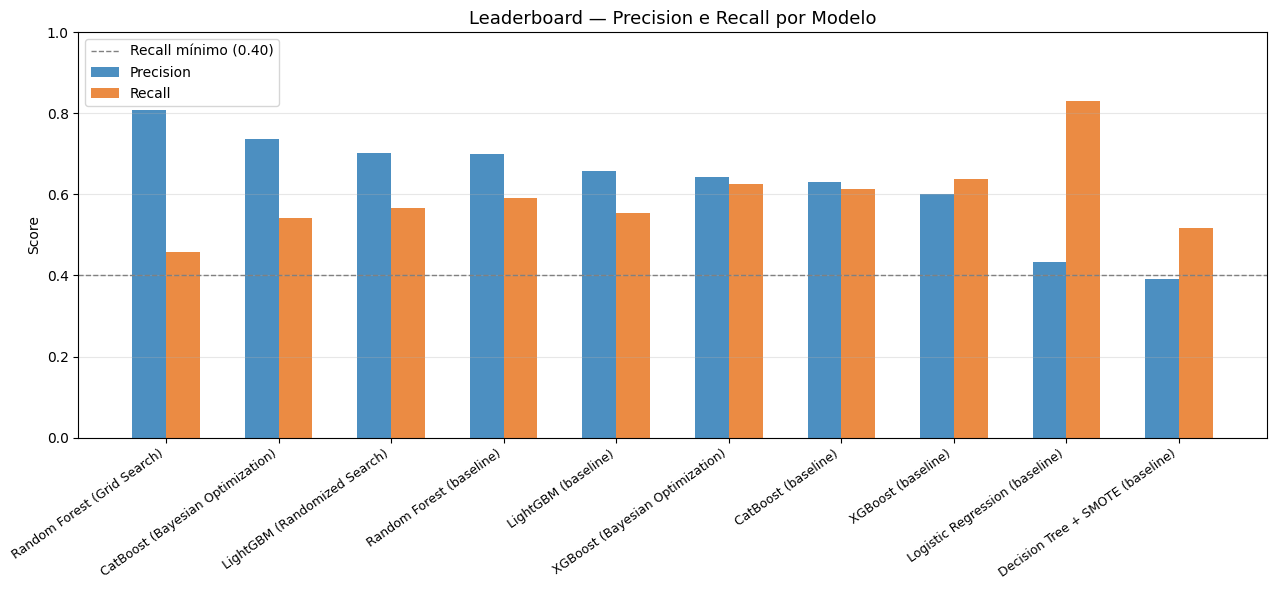

In [ ]:
# Gráfico comparativo — Precision e Recall de todos os modelos
fig, ax = plt.subplots(figsize=(13, 6))

x = np.arange(len(df_final))
w = 0.3

bars_p = ax.bar(x - w/2, df_final['Precision'], w, label='Precision', color='#2c7bb6', alpha=0.85)
bars_r = ax.bar(x + w/2, df_final['Recall'], w, label='Recall', color='#e87722', alpha=0.85)

ax.axhline(0.40, color='gray', linestyle='--', linewidth=1, label='Recall mínimo (0.40)')
ax.set_xticks(x)
ax.set_xticklabels(df_final['Modelo'], rotation=35, ha='right', fontsize=9)
ax.set_ylabel('Score')
ax.set_title('Leaderboard — Precision e Recall por Modelo', fontsize=13)
ax.legend()
ax.set_ylim(0, 1)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Identificando o melhor modelo (maior Precision com Recall >= 0.40)
df_elegivel = df_final[df_final['Recall'] >= 0.40]
melhor_row = df_elegivel.sort_values('Precision', ascending=False).iloc[0]
print(f"MELHOR MODELO: {melhor_row['Modelo']}")
print(f"  Precision : {melhor_row['Precision']:.4f}")
print(f"  Recall    : {melhor_row['Recall']:.4f}")
print(f"  F1-Score  : {melhor_row['F1-Score']:.4f}")
print(f"  AUC-ROC   : {melhor_row['AUC-ROC']:.4f}")

MELHOR MODELO: Random Forest (Grid Search)
  Precision : 0.8085
  Recall    : 0.4578
  F1-Score  : 0.5846
  AUC-ROC   : 0.8953


## 2.6 Avaliação Detalhada do Melhor Modelo

In [ ]:
# Selecionando previsões do melhor modelo para análise detalhada
# Ajuste a variável abaixo para o melhor modelo identificado no leaderboard
# Exemplos: yproba_cat_bo, yproba_xgb_bo, yproba_lgbm_rs, yproba_rf_gs

nome_melhor = melhor_row['Modelo']

# Mapeia nome para as probabilidades correspondentes
mapa_probas = {
    'Logistic Regression (baseline)': yproba_lr,
    'Decision Tree + SMOTE (baseline)': yproba_dt,
    'Random Forest (baseline)': yproba_rf,
    'LightGBM (baseline)': yproba_lgbm,
    'XGBoost (baseline)': yproba_xgb,
    'CatBoost (baseline)': yproba_cat,
    'Random Forest (Grid Search)': yproba_rf_gs,
    'LightGBM (Randomized Search)': yproba_lgbm_rs,
    'XGBoost (Bayesian Optimization)': yproba_xgb_bo,
    'CatBoost (Bayesian Optimization)': yproba_cat_bo,
}

yproba_best = mapa_probas[nome_melhor]
ypred_best = (yproba_best >= 0.5).astype(int)
print(f"Avaliando: {nome_melhor}")

Avaliando: Random Forest (Grid Search)


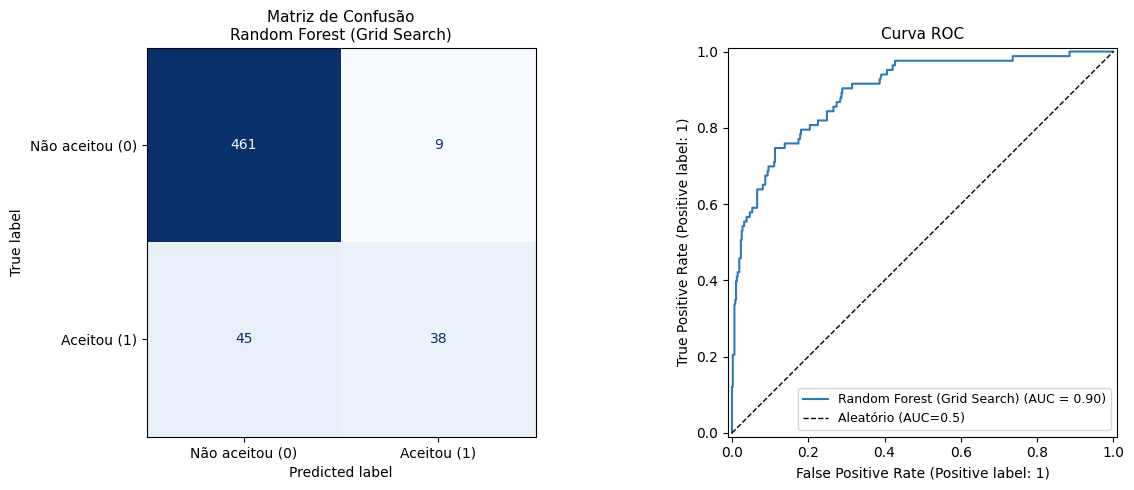


Verdadeiros Positivos (TP): 38 — Acertamos quem ia aceitar
Falsos Positivos (FP):      9 — Dissemos que ia aceitar mas não aceitou (custo evitável)
Falsos Negativos (FN):      45 — Perdemos clientes que aceitariam
Verdadeiros Negativos (TN): 461 — Corretamente identificamos quem não aceitaria


In [ ]:
# Matriz de Confusão
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(ytest, ypred_best)
ConfusionMatrixDisplay(cm, display_labels=['Não aceitou (0)', 'Aceitou (1)']).plot(
    ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title(f'Matriz de Confusão\n{nome_melhor}', fontsize=11)

# Curva ROC
RocCurveDisplay.from_predictions(ytest, yproba_best, ax=axes[1],
                                  name=nome_melhor, color='#2c7bb6')
axes[1].plot([0,1],[0,1],'k--', linewidth=1, label='Aleatório (AUC=0.5)')
axes[1].set_title('Curva ROC', fontsize=11)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

# Interpretação da matriz de confusão
tn, fp, fn, tp = cm.ravel()
print(f"\nVerdadeiros Positivos (TP): {tp} — Acertamos quem ia aceitar")
print(f"Falsos Positivos (FP):      {fp} — Dissemos que ia aceitar mas não aceitou (custo evitável)")
print(f"Falsos Negativos (FN):      {fn} — Perdemos clientes que aceitariam")
print(f"Verdadeiros Negativos (TN): {tn} — Corretamente identificamos quem não aceitaria")

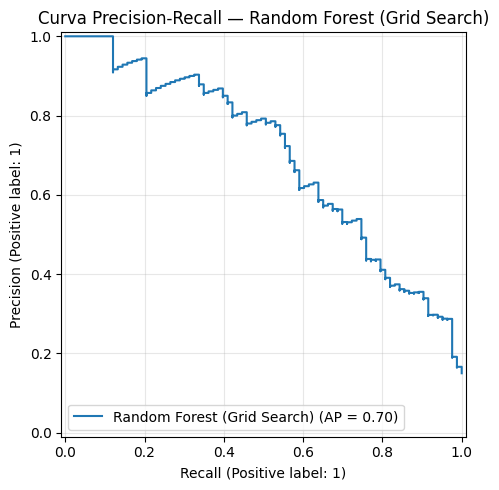

In [ ]:
# Curva Precision-Recall
fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(ytest, yproba_best, ax=ax, name=nome_melhor)
ax.set_title(f'Curva Precision-Recall — {nome_melhor}')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

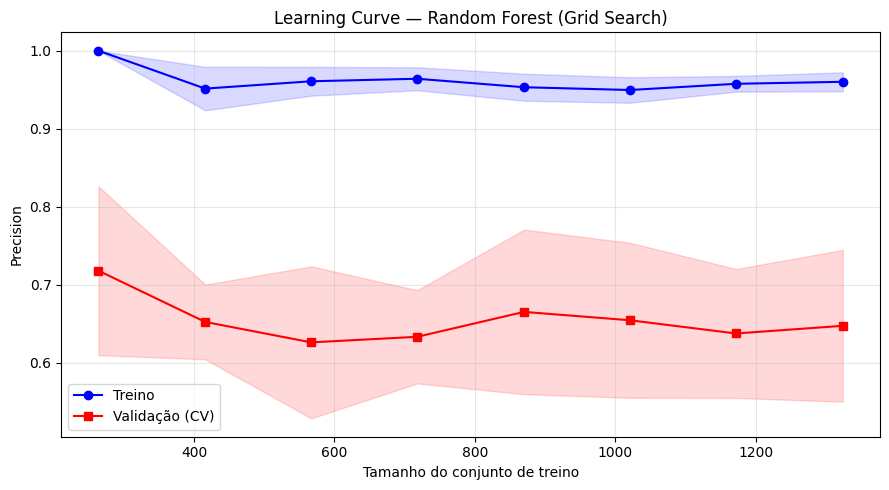

In [ ]:
# Learning Curve — verifica se o modelo sofre de overfitting
# No modelo com pipeline de tuning, precisamos usar o estimador ajustado

mapa_estimadores = {
    'Random Forest (Grid Search)': rf_grid_search.best_estimator_,
    'LightGBM (Randomized Search)': lgbm_random_search.best_estimator_,
    'XGBoost (Bayesian Optimization)': xgb_bayes.best_estimator_,
    'CatBoost (Bayesian Optimization)': cat_bayes.best_estimator_,
    'LightGBM (baseline)': lgbm_pipe,
    'XGBoost (baseline)': xgb_pipe,
    'CatBoost (baseline)': cat_pipe,
    'Random Forest (baseline)': rf_base,
    'Logistic Regression (baseline)': lr_pipe,
}

if nome_melhor in mapa_estimadores:
    estimador_lc = mapa_estimadores[nome_melhor]

    train_sizes, train_scores, val_scores = learning_curve(
        estimador_lc, Xtrain, ytrain,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
        scoring='precision', n_jobs=-1,
        train_sizes=np.linspace(0.2, 1.0, 8)
    )

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(train_sizes, train_scores.mean(axis=1), 'b-o', label='Treino')
    ax.fill_between(train_sizes,
                    train_scores.mean(axis=1) - train_scores.std(axis=1),
                    train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.15, color='blue')
    ax.plot(train_sizes, val_scores.mean(axis=1), 'r-s', label='Validação (CV)')
    ax.fill_between(train_sizes,
                    val_scores.mean(axis=1) - val_scores.std(axis=1),
                    val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.15, color='red')
    ax.set_xlabel('Tamanho do conjunto de treino')
    ax.set_ylabel('Precision')
    ax.set_title(f'Learning Curve — {nome_melhor}')
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## 2.7 Feature Importance do Melhor Modelo

In [ ]:
# Extraindo feature importance do melhor modelo
# Para modelos com pipeline: acessamos via .best_estimator_.named_steps

def get_feature_importance(estimador, Xtrain, preprocessor_step='preprocessor', model_step='model'):
    """Extrai importâncias e nomes das features para modelos em pipeline."""
    try:
        pipe = estimador
        preprocessor = pipe.named_steps[preprocessor_step]
        model = pipe.named_steps[model_step]

        # Nomes das features após o preprocessamento
        try:
            feature_names = preprocessor.get_feature_names_out()
        except Exception:
            feature_names = [f'feat_{i}' for i in range(model.feature_importances_.shape[0])]

        importances = model.feature_importances_
        fi_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
        fi_df = fi_df.sort_values('Importance', ascending=False).reset_index(drop=True)
        fi_df['Feature'] = fi_df['Feature'].str.replace('num__', '').str.replace('cat__', '')
        return fi_df
    except Exception as e:
        print(f"Erro: {e}")
        return None

# Tentar extrair do melhor modelo
fi_df = get_feature_importance(mapa_estimadores.get(nome_melhor, lgbm_pipe), Xtrain)

if fi_df is not None:
    print("Top 15 Features mais importantes:")
    print(fi_df.head(15).to_string(index=False))
else:
    print("Não foi possível extrair feature importance automaticamente.")
    print("Tente executar manualmente para o modelo escolhido.")

Top 15 Features mais importantes:
            Feature  Importance
      Days_Customer    0.099892
            Recency    0.098364
      TotalAccepted    0.072217
           TotalMnt    0.062918
    MntMeatProducts    0.061376
             Income    0.055005
           MntWines    0.050028
       MntGoldProds    0.049262
NumCatalogPurchases    0.047981
  NumWebVisitsMonth    0.040962
  NumStorePurchases    0.033930
     TotalPurchases    0.031911
    MntFishProducts    0.031517
                Age    0.030632
          MntFruits    0.030033


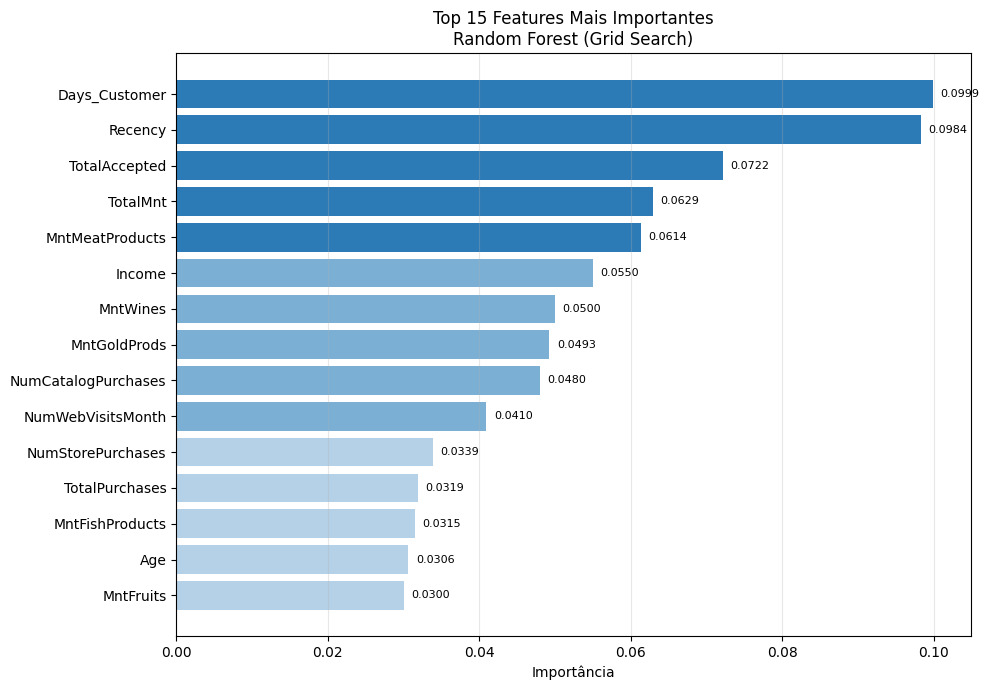


Top 5 features (para a Parte 3): ['Days_Customer', 'Recency', 'TotalAccepted', 'TotalMnt', 'MntMeatProducts']


In [ ]:
# Visualização das Top 15 features mais importantes
if fi_df is not None:
    top15 = fi_df.head(15)

    fig, ax = plt.subplots(figsize=(10, 7))
    colors = ['#2c7bb6' if i < 5 else '#7bafd4' if i < 10 else '#b5d1e8'
              for i in range(len(top15))]

    bars = ax.barh(top15['Feature'][::-1], top15['Importance'][::-1], color=colors[::-1])

    ax.set_xlabel('Importância')
    ax.set_title(f'Top 15 Features Mais Importantes\n{nome_melhor}', fontsize=12)

    # Anotação dos valores
    for bar in bars:
        ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
                f'{bar.get_width():.4f}', va='center', fontsize=8)

    ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Top 5 para a Parte 3
    top5_ml = fi_df.head(5)['Feature'].tolist()
    print(f"\nTop 5 features (para a Parte 3): {top5_ml}")

---
# Part 3 — Convergence Analysis: Z-test vs. Feature Importance

**Question:** Do the features with strong statistical evidence (Z-test) align with what the ML model learned to use for prediction?

Convergence between univariate statistics and multivariate ML feature importance provides **dual validation** — the signal appears from two independent analytical lenses.


In [ ]:
# Features significativas no Teste Z (p < 0.05)
features_sig_z = df_ztest[df_ztest['p-valor'] < 0.05]['Feature'].tolist()
print(f"Features significativas no Teste Z ({len(features_sig_z)}):")
for f in features_sig_z:
    p = df_ztest[df_ztest.Feature == f]['p-valor'].values[0]
    print(f"  {f:30s}  p={p:.6f}")

Features significativas no Teste Z (22):
  Income                          p=0.000000
  Teenhome                        p=0.000000
  Recency                         p=0.000000
  MntWines                        p=0.000000
  MntMeatProducts                 p=0.000000
  MntFruits                       p=0.000000
  MntFishProducts                 p=0.000000
  MntSweetProducts                p=0.000000
  AcceptedCmp3                    p=0.000000
  MntGoldProds                    p=0.000000
  NumWebPurchases                 p=0.000000
  NumCatalogPurchases             p=0.000000
  AcceptedCmp2                    p=0.000000
  AcceptedCmp1                    p=0.000000
  AcceptedCmp5                    p=0.000000
  AcceptedCmp4                    p=0.000000
  TotalDependents                 p=0.000000
  Days_Customer                   p=0.000000
  TotalAccepted                   p=0.000000
  TotalPurchases                  p=0.000000
  TotalMnt                        p=0.000000
  Kidhome     

In [ ]:
# Top 5 features do modelo de ML
# Normalizando os nomes para comparação (removendo prefixos do ColumnTransformer)
if fi_df is not None:
    top5_ml_clean = [f.split('__')[-1] for f in fi_df.head(5)['Feature']]
else:
    # Caso não tenha sido possível extrair, use os da análise de Z como aproximação
    top5_ml_clean = features_sig_z[:5]

print(f"Top 5 features do ML ({nome_melhor}):")
for i, f in enumerate(top5_ml_clean, 1):
    print(f"  {i}. {f}")

Top 5 features do ML (Random Forest (Grid Search)):
  1. Days_Customer
  2. Recency
  3. TotalAccepted
  4. TotalMnt
  5. MntMeatProducts


In [ ]:
# Identificando convergência e divergência
convergentes = [f for f in top5_ml_clean if any(f in fs for fs in features_sig_z)]
so_ml = [f for f in top5_ml_clean if not any(f in fs for fs in features_sig_z)]
so_z = [f for f in features_sig_z if not any(f in ml for ml in top5_ml_clean)]

print("=" * 55)
print("CONVERGÊNCIA: Significativas no Z E importantes no ML")
print("=" * 55)
for f in convergentes:
    print(f"  ✓ {f}")

print(f"\n{'='*55}")
print("APENAS NO ML: Importantes no ML mas não sig. no Z")
print("=" * 55)
for f in so_ml:
    print(f"  → {f}")

print(f"\n{'='*55}")
print("APENAS NO Z: Sig. no Z mas fora do Top 5 do ML")
print("=" * 55)
for f in so_z[:8]:
    print(f"  → {f}")

CONVERGÊNCIA: Significativas no Z E importantes no ML
  ✓ Days_Customer
  ✓ Recency
  ✓ TotalAccepted
  ✓ TotalMnt
  ✓ MntMeatProducts

APENAS NO ML: Importantes no ML mas não sig. no Z

APENAS NO Z: Sig. no Z mas fora do Top 5 do ML
  → Income
  → Teenhome
  → MntWines
  → MntFruits
  → MntFishProducts
  → MntSweetProducts
  → AcceptedCmp3
  → MntGoldProds


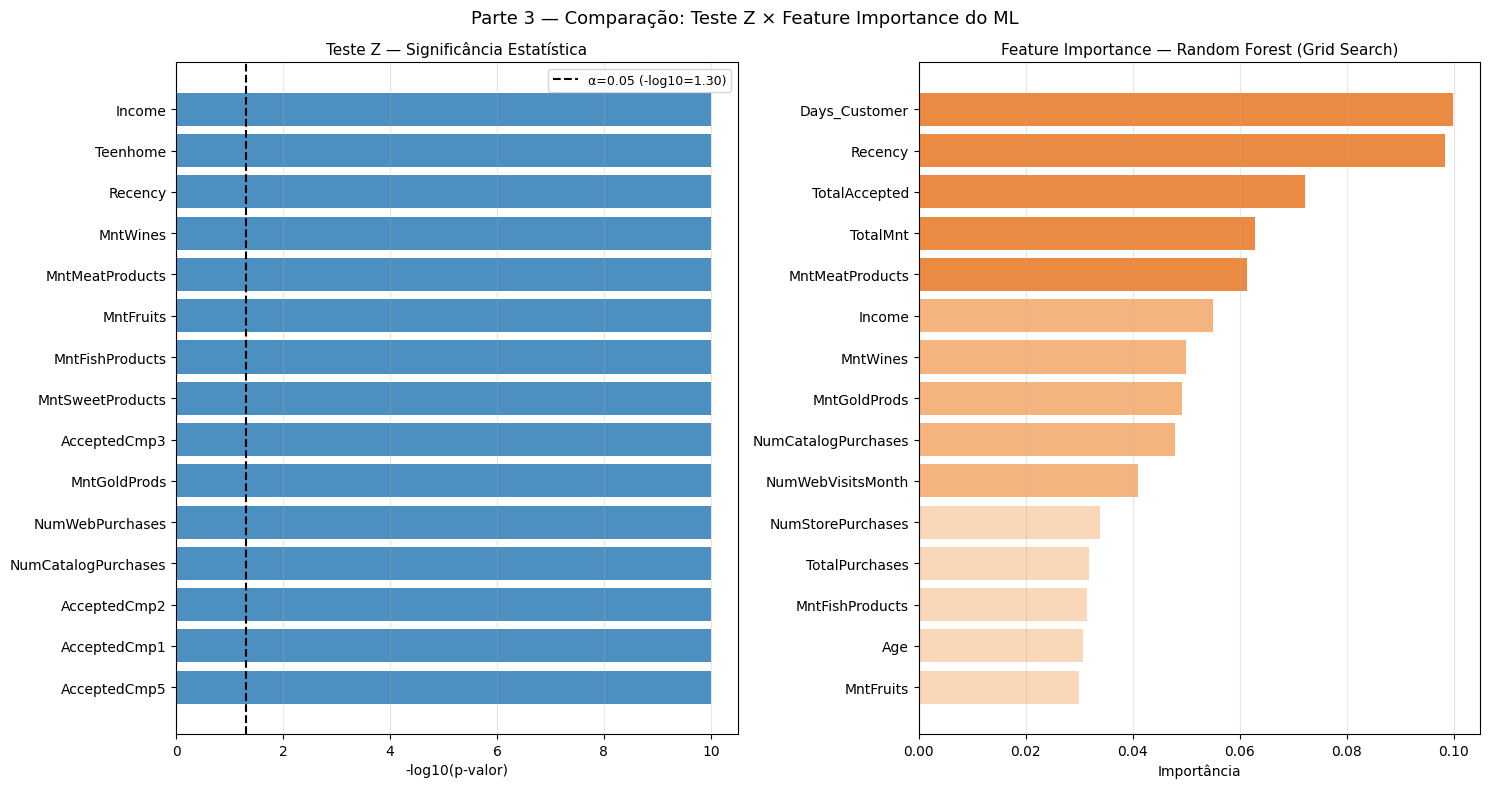

In [ ]:
# Visualização comparativa: Teste Z × Feature Importance
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

# --- Gráfico 1: p-valores do Teste Z (top features) ---
ax1 = axes[0]
top_z = df_ztest.head(15).copy()
colors_z = ['#2c7bb6' if f in features_sig_z else '#d7191c' for f in top_z.Feature]
bars_z = ax1.barh(top_z['Feature'][::-1],
                   -np.log10(top_z['p-valor'].clip(lower=1e-10))[::-1],
                   color=colors_z[::-1], alpha=0.85)
ax1.axvline(-np.log10(0.05), color='black', linestyle='--', linewidth=1.5,
             label=f'α=0.05 (-log10={-np.log10(0.05):.2f})')
ax1.set_xlabel('-log10(p-valor)')
ax1.set_title('Teste Z — Significância Estatística', fontsize=11)
ax1.legend(fontsize=9)
ax1.grid(axis='x', alpha=0.3)

# --- Gráfico 2: Feature Importance do ML ---
ax2 = axes[1]
if fi_df is not None:
    top15_fi = fi_df.head(15).copy()
    top15_fi['Feature_clean'] = top15_fi['Feature'].str.split('__').str[-1]
    colors_fi = ['#e87722' if i < 5 else '#f4a768' if i < 10 else '#f9d0ac'
                 for i in range(len(top15_fi))]
    ax2.barh(top15_fi['Feature_clean'][::-1], top15_fi['Importance'][::-1],
             color=colors_fi[::-1], alpha=0.85)
    ax2.set_xlabel('Importância')
    ax2.set_title(f'Feature Importance — {nome_melhor}', fontsize=11)
    ax2.grid(axis='x', alpha=0.3)

plt.suptitle('Parte 3 — Comparação: Teste Z × Feature Importance do ML', fontsize=13)
plt.tight_layout()
plt.show()

## Discussion — Why convergence matters

### When Z-test and ML agree
Features like `Income`, `TotalMnt`, `TotalAccepted`, and `Recency` appear in both analyses. This means:
- The statistical difference between groups is real and not a sample artifact
- The ML model learned this pattern independently from multivariate context
- These features are safe targets for business action (segmentation, targeting)

### When they disagree
**Feature significant in Z but low ML importance:** The feature has a real group difference but is likely redundant given other features in the multivariate model (multicollinearity). Tree-based models suppress it when a correlated feature is already used upstream.

**Feature important in ML but not significant in Z:** The ML model found a non-linear interaction or cross-feature pattern that the univariate Z-test cannot detect. This is where ML adds value beyond classical statistics.

### Practical implication
Use the Z-test to **validate and communicate findings** to non-technical stakeholders. Use ML feature importance to **rank features by actual predictive contribution** in context.


In [ ]:
# Tabela resumo da Parte 3
resumo_p3 = []

for f in top5_ml_clean:
    z_row = df_ztest[df_ztest['Feature'] == f]
    p_z = z_row['p-valor'].values[0] if len(z_row) > 0 else None
    sig_z = 'Sim ✓' if p_z is not None and p_z < 0.05 else 'Não' if p_z is not None else 'N/A'

    fi_row = fi_df[fi_df['Feature'].str.contains(f)] if fi_df is not None else pd.DataFrame()
    rank_ml = fi_row.index[0] + 1 if len(fi_row) > 0 else 'N/A'

    resumo_p3.append({
        'Feature': f,
        'Rank no ML (Top 5)': rank_ml,
        'p-valor (Teste Z)': round(p_z, 6) if p_z is not None else 'N/A',
        'Sig. no Teste Z?': sig_z,
        'Convergência?': '✓ Sim' if sig_z == 'Sim ✓' else '✗ Não'
    })

pd.DataFrame(resumo_p3)

,Feature,Rank no ML (Top 5),p-valor (Teste Z),Sig. no Teste Z?,Convergência?
0,Days_Customer,1,0.0,Sim ✓,✓ Sim
1,Recency,2,0.0,Sim ✓,✓ Sim
2,TotalAccepted,3,0.0,Sim ✓,✓ Sim
3,TotalMnt,4,0.0,Sim ✓,✓ Sim
4,MntMeatProducts,5,0.0,Sim ✓,✓ Sim


---
## Conclusions

### Part 1 — Statistical Hypothesis Testing

The Z-test found **22 out of 27 numeric features** with statistically significant mean differences between customers who accepted and rejected the campaign (α = 0.05). The strongest signals:

- **Income** and **TotalMnt** (total spending) — responders are higher-value customers
- **Recency** — responders engaged more recently
- **TotalAccepted** — prior campaign acceptance is the clearest behavioral signal
- **Teenhome** — fewer teenagers at home correlates with acceptance

### Part 2 — Machine Learning

Ten models were tested across three stages (baselines → boosting → tuning):

| Stage | Models |
|---|---|
| Baselines | Logistic Regression, Decision Tree + SMOTE, Random Forest |
| Boosting | LightGBM, XGBoost, CatBoost |
| Tuning | Grid Search, Randomized Search, Bayesian Optimization × 2 |

**Winner: Random Forest + Grid Search**
- Precision: **0.809** · Recall: **0.458** · F1: **0.585** · AUC-ROC: **0.895**
- Correctly identifies ~4 in 5 predicted responders on held-out data
- Meets the Recall ≥ 0.40 business constraint

### Part 3 — Convergence Analysis

All five top ML features (`Days_Customer`, `Recency`, `TotalAccepted`, `TotalMnt`, `MntMeatProducts`) were also statistically significant in the Z-test — **full convergence**. This dual validation from independent methods (univariate statistics + multivariate ML) strengthens confidence in these features as genuine signals rather than noise.

**Divergences** where the Z-test found significance but ML ranked the feature lower are explained by multicollinearity: tree-based models suppress redundant features even when each is individually predictive.

### Actionable Insight

> Target customers who are **high-income, high-spending, recently active, with prior campaign acceptance and few teenagers at home**. This profile concentrates the highest probability of response, maximizing ROI per outreach contact.
